# CUDA Differential Evolution — notebook final fusionné

Notebook commun du groupe : compilation, validation CPU/GPU, exploitation des campagnes expérimentales et analyses statistiques.

**Important :** les fichiers `campagne_F1_final.csv` à `campagne_F4_final.csv` constituent la base officielle des résultats. La campagne complète n’a pas besoin d’être relancée sauf modification du code ou du protocole.


## 0. Connexion à Google Drive et dossier de travail


In [1]:
# Sur Colab : monte le Drive et se place dans le dossier du projet.
# En local (WSL, PC) : on reste dans le dossier courant.
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/Projet_CUDA/DE_final')
except ImportError:
    print("Hors Colab : dossier courant conservé ->", os.getcwd())
print(os.listdir('.'))


Mounted at /content/drive
['kernel.h', 'campagne_F4_final.csv', 'main.cpp', 'campagne_F1_final.csv', 'campagne_F2_final.csv', 'kernel.cu', 'campagne_F3_final.csv', 'kernel.cpp', 'images', 'griewank_summary.csv', 'wilcoxon_F3.csv', 'de_app', 'programpso', 'speedup_final.csv', 'summary_final.csv', 'sphere_summary.csv', 'wilcoxon_F1.csv', 'rosenbrock_summary.csv', 'wilcoxon_F2.csv', 'griewank_success_rate.csv', 'rastrigin_summary.csv', 'wilcoxon_F4.csv']


## 1. Vérifier CUDA
Sur Colab avec l’accélérateur GPU activé, `nvcc` doit être disponible.


In [2]:
!nvcc --version


nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0


**Machine utilisée pour la campagne.** Google Colab, Tesla T4.

In [3]:
# Modèle de GPU et de CPU de la machine
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
!lscpu | grep "Model name"


name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz


## 2. Compiler les quatre fichiers finaux
Les fichiers utilisés sont : `kernel.h`, `kernel.cpp`, `kernel.cu` et `main.cpp`.


In [4]:
!nvcc -std=c++17 -O2 -o de_app main.cpp kernel.cpp kernel.cu


In [5]:
# Test avec la commande exacte du prof (doit afficher Ok)
!nvcc -o programpso main.cpp kernel.cpp kernel.cu && echo Ok


Ok


## 3. Tests rapides de validation
Le mode `both` exécute CPU et GPU sur la même configuration, avec la même seed et la même population initiale. Ces tests servent uniquement à vérifier que le programme fonctionne avant l’analyse des campagnes.


In [6]:
# Test rapide général
!./de_app 10 50 1 3 both 123456789

# Test Rosenbrock
!./de_app 50 100 2 3 both 123456789


func,dim,pop,run,error,time_ms,mode,seed
1,10,50,1,0.000000e+00,53.730,cpu,123456789
1,10,50,1,0.000000e+00,36.545,gpu,123456789
# pair run=1 speedup_cpu_over_gpu=1.4702
1,10,50,2,0.000000e+00,52.686,cpu,123456790
1,10,50,2,0.000000e+00,36.541,gpu,123456790
# pair run=2 speedup_cpu_over_gpu=1.4418
1,10,50,3,0.000000e+00,55.834,cpu,123456791
1,10,50,3,0.000000e+00,37.956,gpu,123456791
# pair run=3 speedup_cpu_over_gpu=1.4710
# cpu F1 D=10 NP=50 | error mean=0.000000e+00 std=0.000000e+00 | time mean=54.083 ms std=1.603
# gpu F1 D=10 NP=50 | error mean=0.000000e+00 std=0.000000e+00 | time mean=37.014 ms std=0.816
# speedup paired_mean=1.4610 ratio_of_mean_times=1.4612
func,dim,pop,run,error,time_ms,mode,seed
2,50,100,1,4.096824e+01,647.630,cpu,123456789
2,50,100,1,4.097990e+01,145.343,gpu,123456789
# pair run=1 speedup_cpu_over_gpu=4.4559
2,50,100,2,4.170077e+01,641.416,cpu,123456790
2,50,100,2,4.104827e+01,145.491,gpu,123456790
# pair run=2 speedup_cpu_over_gpu=4.4086
2,50,100,3,4.725744

## 4. Campagne complète — déjà exécutée

Protocole :
- 4 fonctions : Sphere, Rosenbrock, Griewank, Rastrigin
- Dimensions : 10, 50, 100
- Populations : 50, 100, 500
- 10 runs
- CPU + GPU
- `MaxFES = 10^4 × D`

Soit **720 lignes de résultats** au total.

La cellule ci-dessous est volontairement désactivée pour éviter de relancer la campagne par erreur.


In [ ]:
# %%bash
# set -e
# for f in 1 2 3 4; do
#   out="campagne_F${f}_final.csv"
#   echo "func,dim,pop,run,error,time_ms,mode,seed" > "$out"
#   for d in 10 50 100; do
#     for p in 50 100 500; do
#       ./de_app "$d" "$p" "$f" 10 both 123456789 | grep -E '^[0-9]+,' >> "$out"
#     done
#   done
# done


## 5. Charger et vérifier les résultats


In [7]:
import pandas as pd
import numpy as np

frames = []
for f in [1, 2, 3, 4]:
    df = pd.read_csv(f"campagne_F{f}_final.csv")
    frames.append(df)
    print(f"F{f}: {len(df)} lignes (attendu 180)")

all_df = pd.concat(frames, ignore_index=True)

print('Total :', len(all_df), 'lignes (attendu 720)')
print('Runs par configuration :', all_df.groupby(['func','dim','pop','mode']).size().unique(), '(attendu [10])')
print('Nombre de NaN :', int(all_df.isna().sum().sum()))

all_df.head()


F1: 180 lignes (attendu 180)
F2: 180 lignes (attendu 180)
F3: 180 lignes (attendu 180)
F4: 180 lignes (attendu 180)
Total : 720 lignes (attendu 720)
Runs par configuration : [10] (attendu [10])
Nombre de NaN : 0


,func,dim,pop,run,error,time_ms,mode,seed
0,1,10,50,1,0.0,59.421,cpu,123456789
1,1,10,50,1,0.0,32.408,gpu,123456789
2,1,10,50,2,0.0,59.493,cpu,123456790
3,1,10,50,2,0.0,32.395,gpu,123456790
4,1,10,50,3,0.0,59.080,cpu,123456791


## 6. Synthèse statistique globale


In [8]:
summary = (
    all_df.groupby(['func','dim','pop','mode'])
    .agg(
        error_mean=('error','mean'),
        error_std=('error','std'),
        time_mean_ms=('time_ms','mean'),
        time_std_ms=('time_ms','std')
    )
    .reset_index()
)

display(summary)


,func,dim,pop,mode,error_mean,error_std,time_mean_ms,time_std_ms
0,1,10,50,cpu,0.000000e+00,0.000000e+00,59.8181,2.054487
1,1,10,50,gpu,0.000000e+00,0.000000e+00,31.8815,0.349012
2,1,10,100,cpu,2.408342e-41,2.674652e-41,37.8947,2.135013
3,1,10,100,gpu,1.799239e-41,1.382399e-41,15.2860,0.043094
4,1,10,500,cpu,8.484068e-06,2.173443e-06,32.5888,0.392310
...,...,...,...,...,...,...,...,...
67,4,100,50,gpu,5.431570e+02,1.454382e+01,1196.5423,9.075573
68,4,100,100,cpu,5.890505e+02,1.598498e+01,3736.5446,31.993642
69,4,100,100,gpu,5.874007e+02,1.758044e+01,761.8222,13.182285
70,4,100,500,cpu,7.086866e+02,2.657703e+01,3734.6660,27.414455


## 7. Speedup CPU/GPU
Le speedup est calculé run par run à partir des temps appariés :

\[
Speedup = \frac{T_{CPU}}{T_{GPU}}
\]


In [9]:
cpu = all_df[all_df['mode'] == 'cpu'].copy()
gpu = all_df[all_df['mode'] == 'gpu'].copy()

paired = cpu.merge(
    gpu,
    on=['func','dim','pop','run','seed'],
    suffixes=('_cpu','_gpu')
)

paired['speedup'] = paired['time_ms_cpu'] / paired['time_ms_gpu']

speedup = (
    paired.groupby(['func','dim','pop'])['speedup']
    .agg(['mean','std'])
    .reset_index()
)

display(speedup)


,func,dim,pop,mean,std
0,1,10,50,1.876591,0.071788
1,1,10,100,2.479004,0.138768
2,1,10,500,10.308058,0.126030
3,1,50,50,5.063250,0.048601
4,1,50,100,5.031406,0.178848
5,1,50,500,11.158997,4.886230
6,1,100,50,4.470701,0.101404
7,1,100,100,3.630508,0.082288
8,1,100,500,9.080516,0.610201
9,2,10,50,1.968325,0.060265


## 8. Sauvegarder les tableaux globaux


In [10]:
summary.to_csv('summary_final.csv', index=False)
speedup.to_csv('speedup_final.csv', index=False)
print('summary_final.csv et speedup_final.csv créés')


summary_final.csv et speedup_final.csv créés


## 9. Tests statistiques globaux

### 9.1 Wilcoxon apparié : CPU vs GPU
Les runs CPU et GPU sont appariés par `func`, `dim`, `pop`, `run` et `seed`. On utilise donc le **test de Wilcoxon signed-rank** sur les erreurs.

- H0 : pas de différence systématique entre CPU et GPU.
- Si `p < 0.05` : différence statistiquement significative.


In [11]:
from scipy.stats import wilcoxon, kruskal

noms = {1:'Sphere', 2:'Rosenbrock', 3:'Griewank', 4:'Rastrigin'}

rows = []
for (f, d, p), sub in paired.groupby(['func','dim','pop']):
    a = sub['error_cpu'].to_numpy()
    b = sub['error_gpu'].to_numpy()

    if np.allclose(a, b):
        stat, pv, conclusion = 0.0, 1.0, 'résultats identiques'
    else:
        stat, pv = wilcoxon(a, b)
        conclusion = 'différence significative' if pv < 0.05 else 'pas de différence significative'

    rows.append({
        'fonction': noms[f],
        'dim': d,
        'pop': p,
        'W': stat,
        'p_value': pv,
        'conclusion': conclusion
    })

wilcoxon_global = pd.DataFrame(rows)
display(wilcoxon_global)


,fonction,dim,pop,W,p_value,conclusion
0,Sphere,10,50,0.0,1.000000,résultats identiques
1,Sphere,10,100,0.0,1.000000,résultats identiques
2,Sphere,10,500,25.0,0.845703,pas de différence significative
3,Sphere,50,50,0.0,1.000000,résultats identiques
4,Sphere,50,100,0.0,1.000000,résultats identiques
5,Sphere,50,500,7.0,0.037109,différence significative
6,Sphere,100,50,0.0,1.000000,résultats identiques
7,Sphere,100,100,0.0,1.000000,résultats identiques
8,Sphere,100,500,16.0,0.275391,pas de différence significative
9,Rosenbrock,10,50,13.0,0.160156,pas de différence significative


**Lecture du Wilcoxon apparié (fonctions 1 à 4).** Les 36 comparaisons sont faites au seuil de 5 %. Deux seulement sont significatives : Rosenbrock D=10 / NP=100 (p ≈ 0,049) et Sphere D=50 / NP=500 (p ≈ 0,037). Avec 25 à 36 tests à 5 %, on attend 1 à 2 faux positifs par pur hasard : ces deux cas sont isolés et ne remettent pas en cause l'équivalence de qualité CPU/GPU.

Note de méthode : quand les erreurs CPU et GPU sont identiques à 10⁻⁸ près (`np.allclose`), le test n'est pas calculé et on affiche « résultats identiques » (p = 1).


### 9.2 Kruskal–Wallis : effet de la taille de population
Pour chaque fonction, dimension et mode, on compare les erreurs obtenues avec `NP = 50, 100, 500`.

- H0 : les trois populations ont le même comportement.
- Si `p < 0.05` : la taille de population a un effet statistiquement détectable.


In [12]:
pops = [50, 100, 500]
rows = []

for (f, d, m), sub in all_df.groupby(['func','dim','mode']):
    groupes = [sub[sub['pop'] == p]['error'].to_numpy() for p in pops]

    if np.ptp(np.concatenate(groupes)) == 0:
        pv, conclusion = 1.0, 'résultats identiques'
    else:
        pv = kruskal(*groupes).pvalue
        conclusion = "NP influence l'erreur" if pv < 0.05 else "pas d'effet détecté"

    rows.append({
        'fonction': noms[f],
        'dim': d,
        'mode': m,
        'p_value': pv,
        'conclusion': conclusion
    })

kruskal_global = pd.DataFrame(rows)
display(kruskal_global)


,fonction,dim,mode,p_value,conclusion
0,Sphere,10,cpu,0.000002,NP influence l'erreur
1,Sphere,10,gpu,0.000002,NP influence l'erreur
2,Sphere,50,cpu,0.000002,NP influence l'erreur
3,Sphere,50,gpu,0.000002,NP influence l'erreur
4,Sphere,100,cpu,0.000002,NP influence l'erreur
5,Sphere,100,gpu,0.000002,NP influence l'erreur
6,Rosenbrock,10,cpu,0.000010,NP influence l'erreur
7,Rosenbrock,10,gpu,0.000005,NP influence l'erreur
8,Rosenbrock,50,cpu,0.000020,NP influence l'erreur
9,Rosenbrock,50,gpu,0.000015,NP influence l'erreur


## 10. Outils communs pour l’analyse détaillée des quatre fonctions

Toutes les fonctions suivent exactement le même pipeline :

1. filtrer les résultats CPU et GPU ;
2. construire un tableau CPU/GPU fusionné ;
3. tracer les temps CPU vs GPU ;
4. tracer le speedup ;
5. tracer les erreurs CPU vs GPU ;
6. tracer les erreurs en échelle logarithmique lorsque cela est possible ;
7. appliquer le test de Wilcoxon apparié sur les erreurs ;
8. sauvegarder le tableau et le test statistique.

L’interprétation scientifique reste ensuite propre à chaque fonction.


In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

os.makedirs("images", exist_ok=True)

noms = {
    1: "Sphere",
    2: "Rosenbrock",
    3: "Griewank",
    4: "Rastrigin"
}

pops = [50, 100, 500]

# Erreurs moyennes publiées dans l'article (colonnes : NP = 50, 100, 500), clé = (fonction, dimension)
paper = {
    (1,10):(0,0,0), (1,50):(0,0,0), (1,100):(0,0,0),
    (2,10):(0.388,0.044,1.306), (2,50):(213.544,12.244,46.968), (2,100):(15.720,42.293,113.292),
    (3,10):(0,0,0), (3,50):(0.001,0,0), (3,100):(0.002,0.005,0),
    (4,10):(0,0,0), (4,50):(18.286,2.936,28.345), (4,100):(63.166,48.329,40.891),
}

def preparer_table_fonction(f):
    """Filtre CPU/GPU et construit le tableau final d'une fonction."""
    sf = summary[summary["func"] == f].copy()
    spf = speedup[speedup["func"] == f].copy()

    cpu_f = sf[sf["mode"] == "cpu"].copy()
    gpu_f = sf[sf["mode"] == "gpu"].copy()

    table = cpu_f.merge(
        gpu_f,
        on=["func", "dim", "pop"],
        suffixes=("_cpu", "_gpu")
    )

    table = table.merge(
        spf,
        on=["func", "dim", "pop"]
    )

    table = table[
        [
            "dim", "pop",
            "error_mean_cpu", "error_std_cpu",
            "error_mean_gpu", "error_std_gpu",
            "time_mean_ms_cpu", "time_mean_ms_gpu",
            "mean", "std"
        ]
    ]

    table = table.rename(columns={
        "dim": "Dimension",
        "pop": "Population",
        "error_mean_cpu": "Erreur moyenne CPU",
        "error_std_cpu": "Ecart-type erreur CPU",
        "error_mean_gpu": "Erreur moyenne GPU",
        "error_std_gpu": "Ecart-type erreur GPU",
        "time_mean_ms_cpu": "Temps moyen CPU (ms)",
        "time_mean_ms_gpu": "Temps moyen GPU (ms)",
        "mean": "Speedup moyen",
        "std": "Ecart-type speedup"
    })

    # Comparaison avec l'article (erreur moyenne publiée)
    table["Erreur article"] = [paper[(f, d)][pops.index(p)]
                               for d, p in zip(table["Dimension"], table["Population"])]

    return table


def tracer_temps(table, nom):
    for dim in sorted(table["Dimension"].unique()):
        sub = table[table["Dimension"] == dim]

        plt.figure(figsize=(7,4))
        plt.plot(sub["Population"], sub["Temps moyen CPU (ms)"], marker="o", label="CPU")
        plt.plot(sub["Population"], sub["Temps moyen GPU (ms)"], marker="o", label="GPU")

        plt.xlabel("Population")
        plt.ylabel("Temps moyen (ms)")
        plt.title(f"{nom} - Temps CPU vs GPU - D={dim}")
        plt.legend()
        plt.grid(True)
        plt.savefig(f"images/{nom}_temps_D{dim}.png", dpi=200, bbox_inches="tight")
        plt.show()


def tracer_speedup(table, nom):
    for dim in sorted(table["Dimension"].unique()):
        sub = table[table["Dimension"] == dim]

        plt.figure(figsize=(7,4))
        plt.plot(sub["Population"], sub["Speedup moyen"], marker="o")

        plt.xlabel("Population")
        plt.ylabel("Speedup moyen")
        plt.title(f"{nom} - Speedup CPU/GPU - D={dim}")
        plt.grid(True)
        plt.savefig(f"images/{nom}_speedup_D{dim}.png", dpi=200, bbox_inches="tight")
        plt.show()


def tracer_erreurs(table, nom, log=False):
    for dim in sorted(table["Dimension"].unique()):
        sub = table[table["Dimension"] == dim]

        plt.figure(figsize=(7,4))
        plt.plot(sub["Population"], sub["Erreur moyenne CPU"], marker="o", label="CPU")
        plt.plot(sub["Population"], sub["Erreur moyenne GPU"], marker="o", label="GPU")

        if log:
            # L'échelle logarithmique n'accepte pas les valeurs nulles.
            if (sub["Erreur moyenne CPU"] > 0).all() and (sub["Erreur moyenne GPU"] > 0).all():
                plt.yscale("log")
                ylabel = "Erreur moyenne - échelle logarithmique"
            else:
                ylabel = "Erreur moyenne"
        else:
            ylabel = "Erreur moyenne"

        plt.xlabel("Population")
        plt.ylabel(ylabel)
        suffixe = " - échelle logarithmique" if log and "logarithmique" in ylabel else ""
        plt.title(f"{nom} - Erreur CPU vs GPU - D={dim}{suffixe}")
        plt.legend()
        plt.grid(True)
        etiquette = "log" if (log and "logarithmique" in ylabel) else "lin"
        plt.savefig(f"images/{nom}_erreur_{etiquette}_D{dim}.png", dpi=200, bbox_inches="tight")
        plt.show()


def wilcoxon_fonction(f):
    """Wilcoxon apparié CPU/GPU, configuration par configuration."""
    rows = []

    pf = paired[paired["func"] == f].copy()

    for dim in sorted(pf["dim"].unique()):
        for pop in sorted(pf[pf["dim"] == dim]["pop"].unique()):
            sub = pf[(pf["dim"] == dim) & (pf["pop"] == pop)]

            x = sub["error_cpu"].to_numpy()
            y = sub["error_gpu"].to_numpy()

            # scipy peut échouer si toutes les différences sont exactement nulles.
            if np.allclose(x, y):
                stat, pvalue = 0.0, 1.0
            else:
                stat, pvalue = wilcoxon(x, y)

            rows.append({
                "Dimension": dim,
                "Population": pop,
                "Statistique W": stat,
                "p-value": pvalue
            })

    return pd.DataFrame(rows)


def sauvegarder_analyse_fonction(f, table, wilcoxon_table):
    nom_fichier = noms[f].lower()
    table.to_csv(f"{nom_fichier}_summary.csv", index=False)
    wilcoxon_table.to_csv(f"wilcoxon_F{f}.csv", index=False)
    print(f"{nom_fichier}_summary.csv et wilcoxon_F{f}.csv créés")


### Outils complémentaires
Tableau de synthèse (moyenne ± écart-type), figure en trois panneaux (échelle qui accepte les erreurs égales à 0) et taux de succès comparable à celui de l'article. Ces fonctions s'appliquent aux quatre fonctions de test ; chaque section n'a qu'à les appeler.

In [14]:
# Outils complémentaires (définitions seulement, utilisables pour les 4 fonctions)
dims = [10, 50, 100]

# Taux de succès publiés dans l'article (colonnes : NP = 50, 100, 500), clé = (fonction, dimension)
sr_paper = {
    (1,10):(1.00,1.00,1.00), (1,50):(1.00,1.00,1.00), (1,100):(1.00,1.00,1.00),
    (2,10):(0.44,0.32,0.00), (2,50):(0.00,0.04,0.00), (2,100):(0.00,0.00,0.00),
    (3,10):(1.00,1.00,1.00), (3,50):(0.92,1.00,1.00), (3,100):(0.84,0.96,0.96),
    (4,10):(1.00,1.00,1.00), (4,50):(0.00,0.04,0.04), (4,100):(0.00,0.00,0.00),
}

def tableau_moy_std(f):
    """Tableau de synthèse d'une fonction : erreurs (moyenne ± écart-type), temps, speedup, erreur de l'article."""
    s = summary[summary["func"] == f]
    c = s[s["mode"] == "cpu"].set_index(["dim", "pop"])
    g = s[s["mode"] == "gpu"].set_index(["dim", "pop"])
    sp = speedup[speedup["func"] == f].set_index(["dim", "pop"])["mean"]
    out = pd.DataFrame(index=c.index)
    out["Erreur CPU (moy ± std)"] = [f"{m:.3g} ± {sd:.2g}" for m, sd in zip(c["error_mean"], c["error_std"])]
    out["Erreur GPU (moy ± std)"] = [f"{m:.3g} ± {sd:.2g}" for m, sd in zip(g["error_mean"], g["error_std"])]
    out["Temps CPU (ms)"] = c["time_mean_ms"].round(1)
    out["Temps GPU (ms)"] = g["time_mean_ms"].round(1)
    out["Speedup"] = sp.round(2)
    out["Erreur article"] = [paper[(f, d)][pops.index(p)] for d, p in out.index]
    return out

def figure_synthese(f):
    """Figure de synthèse : temps CPU/GPU (log), speedup, erreur CPU/GPU (symlog : accepte les erreurs nulles)."""
    s = summary[summary["func"] == f]
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for i, d in enumerate(dims):
        col = f"C{i}"
        c = s[(s["dim"] == d) & (s["mode"] == "cpu")].set_index("pop")
        g = s[(s["dim"] == d) & (s["mode"] == "gpu")].set_index("pop")
        sp = speedup[(speedup["func"] == f) & (speedup["dim"] == d)].set_index("pop")["mean"]
        ax[0].plot(pops, c["time_mean_ms"], "--s", color=col, label=f"CPU D={d}")
        ax[0].plot(pops, g["time_mean_ms"], "-o", color=col, label=f"GPU D={d}")
        ax[1].plot(pops, sp, "-o", color=col, label=f"D={d}")
        ax[2].plot(pops, c["error_mean"], "--s", color=col, label=f"CPU D={d}")
        ax[2].plot(pops, g["error_mean"], "-o", color=col, label=f"GPU D={d}")
    ax[0].set_title(f"{noms[f]} : temps CPU vs GPU"); ax[0].set_ylabel("Temps moyen (ms)"); ax[0].set_yscale("log")
    ax[1].set_title(f"{noms[f]} : speedup"); ax[1].set_ylabel("T_CPU / T_GPU"); ax[1].axhline(1, color="gray", ls="--", lw=1)
    ax[2].set_title(f"{noms[f]} : erreur CPU vs GPU"); ax[2].set_ylabel("Erreur moyenne"); ax[2].set_yscale("symlog", linthresh=1e-3)
    for a in ax:
        a.set_xscale("log"); a.set_xticks(pops); a.set_xticklabels(pops); a.minorticks_off()
        a.set_xlabel("Taille de population NP"); a.grid(alpha=.3); a.legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(f"images/{noms[f]}_3panneaux.png", dpi=200, bbox_inches="tight")
    plt.show()

def taux_succes(f, seuil=1e-8):
    """Taux de succès (proportion de runs avec erreur < seuil), comparé à l'article."""
    d = all_df[all_df["func"] == f].copy()
    d["succes"] = d["error"] < seuil
    sr = d.groupby(["dim", "pop", "mode"])["succes"].mean().unstack("mode").reset_index()
    sr = sr.rename(columns={"cpu": "Succès CPU", "gpu": "Succès GPU", "dim": "Dimension", "pop": "Population"})
    sr["Succès article"] = [sr_paper[(f, dd)][pops.index(p)] for dd, p in zip(sr["Dimension"], sr["Population"])]
    return sr


## 11. Analyse détaillée par fonction

Répartition :
- **F1 Sphere** — Khadija
- **F2 Rosenbrock** — Naima
- **F3 Griewank** — Taha
- **F4 Rastrigin** — Khadia

Chaque fonction suit désormais exactement les mêmes calculs. Seule l’interprétation rédigée change selon le comportement observé.


### 11.1 F1 — Sphere — Khadija


In [15]:
# 1. Filtrage CPU/GPU et tableau fusionné
f1_table = preparer_table_fonction(1)
display(f1_table)


,Dimension,Population,Erreur moyenne CPU,Ecart-type erreur CPU,Erreur moyenne GPU,Ecart-type erreur GPU,Temps moyen CPU (ms),Temps moyen GPU (ms),Speedup moyen,Ecart-type speedup,Erreur article
0,10,50,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,59.8181,31.8815,1.876591,0.071788,0
1,10,100,2.408342e-41,2.674652e-41,1.799239e-41,1.382399e-41,37.8947,15.2860,2.479004,0.138768,0
2,10,500,8.484068e-06,2.173443e-06,8.368925e-06,2.609262e-06,32.5888,3.1617,10.308058,0.126030,0
3,50,50,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1286.6271,254.1108,5.063250,0.048601,0
4,50,100,4.823830e-39,2.104224e-39,4.828276e-39,2.147572e-39,721.8569,143.4703,5.031406,0.178848,0
5,50,500,3.594449e-04,2.973926e-05,3.806835e-04,2.295708e-05,736.4259,72.4204,11.158997,4.886230,0
6,100,50,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4477.4583,1001.5985,4.470701,0.101404,0
7,100,100,1.443324e-27,5.652489e-28,1.510774e-27,4.650284e-28,2500.8091,689.0911,3.630508,0.082288,0
8,100,500,1.889921e-01,1.720715e-02,1.818029e-01,1.342105e-02,2494.0176,275.6223,9.080516,0.610201,0


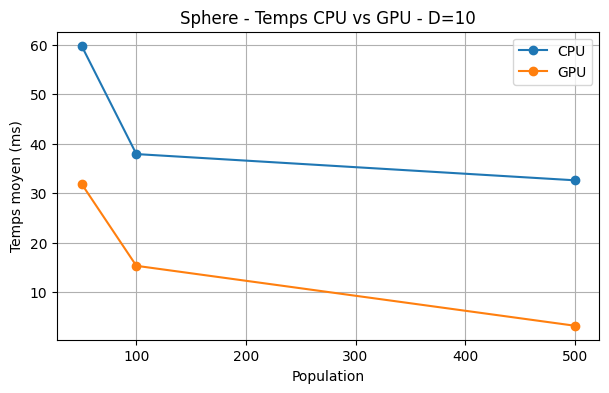

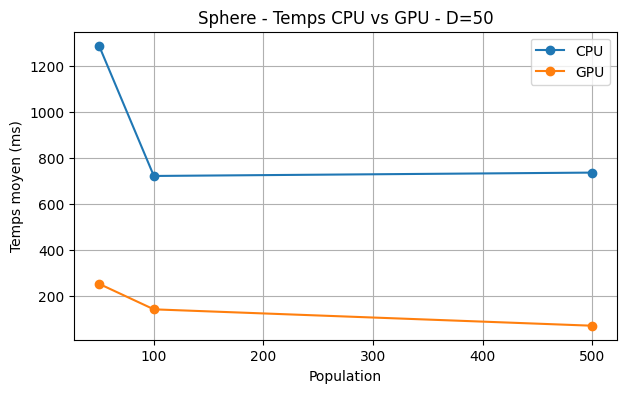

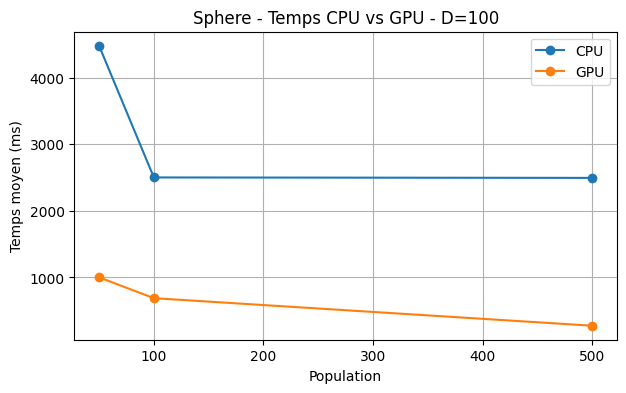

In [16]:
# 2. Temps CPU vs GPU
tracer_temps(f1_table, "Sphere")


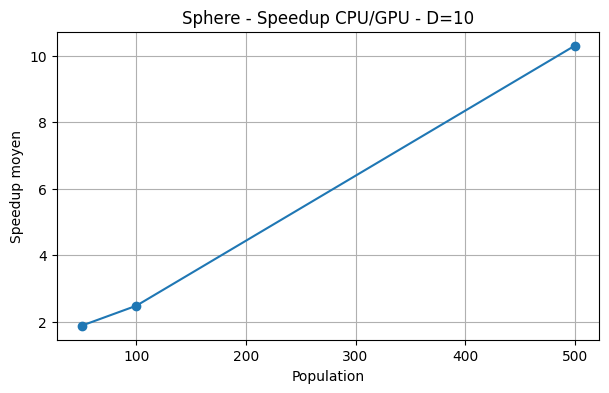

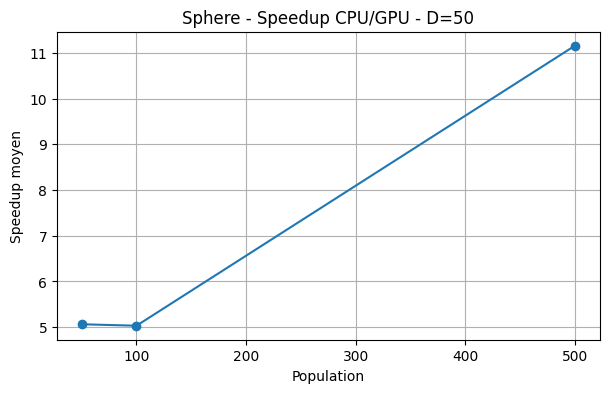

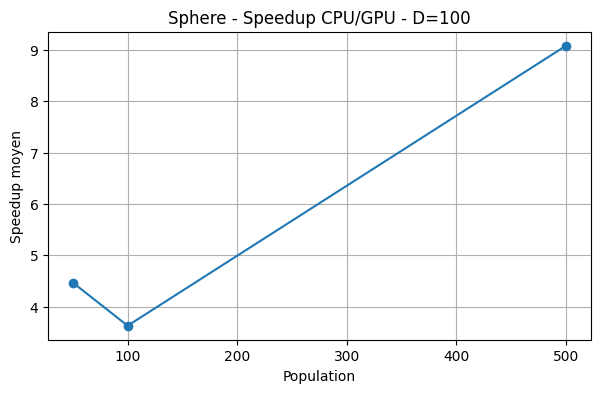

In [17]:
# 3. Speedup CPU/GPU
tracer_speedup(f1_table, "Sphere")


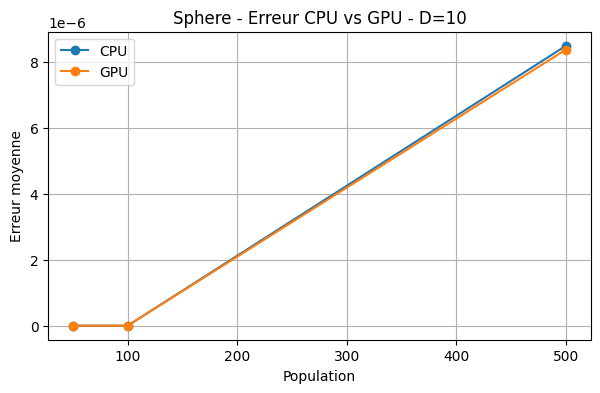

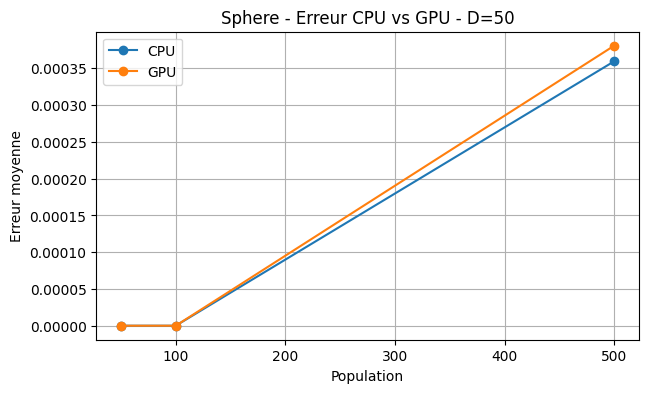

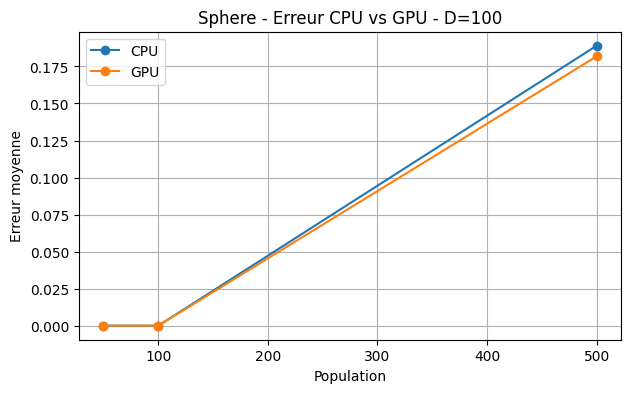

In [18]:
# 4. Erreurs CPU vs GPU
tracer_erreurs(f1_table, "Sphere", log=False)


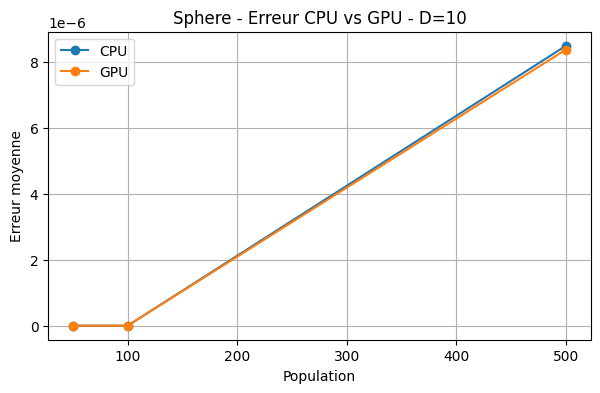

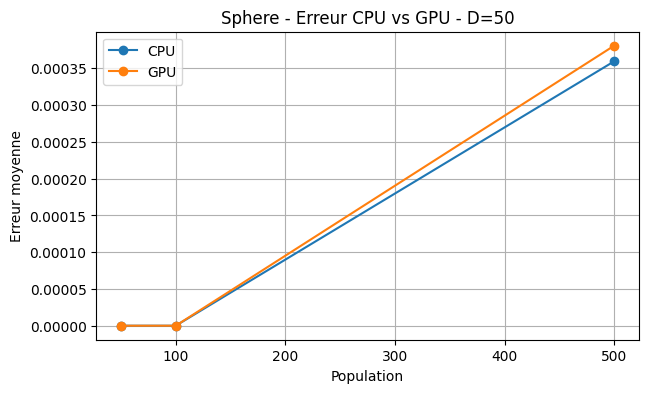

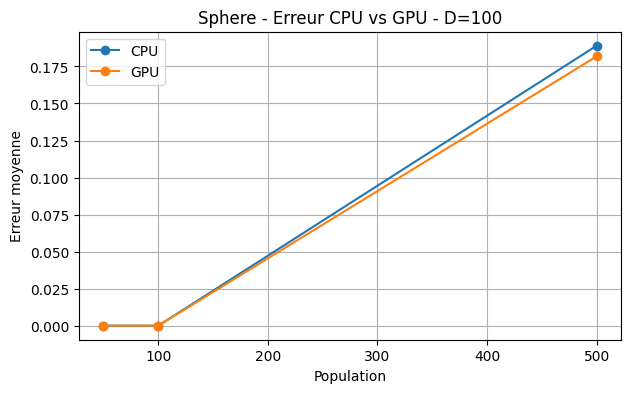

In [19]:
# 5. Erreurs CPU vs GPU en échelle logarithmique si possible
tracer_erreurs(f1_table, "Sphere", log=True)


In [20]:
# 6. Test de Wilcoxon apparié CPU/GPU
wilcoxon_f1 = wilcoxon_fonction(1)
display(wilcoxon_f1)


,Dimension,Population,Statistique W,p-value
0,10,50,0.0,1.000000
1,10,100,0.0,1.000000
2,10,500,25.0,0.845703
3,50,50,0.0,1.000000
4,50,100,0.0,1.000000
5,50,500,7.0,0.037109
6,100,50,0.0,1.000000
7,100,100,0.0,1.000000
8,100,500,16.0,0.275391


### Test statistique de Wilcoxon — Sphere

Le test de Wilcoxon apparié a été appliqué afin de comparer les erreurs d'optimisation des versions CPU et GPU, avec un seuil de significativité de 5 %.

Pour huit configurations sur neuf, les p-values sont supérieures à 0,05. Aucune différence statistiquement significative n'est donc détectée entre les deux implémentations.

Une seule configuration, D = 50 et NP = 500, présente une différence significative (p ≈ 0,037). Ce résultat reste isolé et doit être interprété avec prudence, notamment en raison du nombre de comparaisons réalisées.

Globalement, le test ne met pas en évidence de différence systématique de qualité entre les versions CPU et GPU sur Sphere.

In [21]:
# 7. Sauvegarde des résultats détaillés
sauvegarder_analyse_fonction(1, f1_table, wilcoxon_f1)


sphere_summary.csv et wilcoxon_F1.csv créés


**Interprétation : Shifted Sphere**

Les résultats expérimentaux montrent que l'algorithme Differential Evolution atteint une bonne précision sur la fonction Sphere, particulièrement pour les faibles dimensions.

Pour une dimension de 10 et une population de 50 individus, les erreurs moyennes CPU et GPU sont nulles à la précision enregistrée.

Lorsque la dimension augmente, l'optimisation devient plus difficile. Par exemple, pour D = 100 et NP = 500, l'erreur moyenne est de 0,189 sur CPU et de 0,182 sur GPU. Les écarts-types correspondants sont de 0,0172 et 0,0134, ce qui indique une dispersion relativement faible des erreurs dans cette configuration.

Concernant le temps d'exécution, le GPU présente un avantage important. Pour D = 100 et NP = 500, le temps moyen passe de 2 494,02 ms sur CPU à 275,62 ms sur GPU, avec un speedup moyen enregistré de 9,08.

**Conclusion :** l'implémentation CUDA permet d'accélérer Differential Evolution tout en conservant une précision comparable à celle du CPU sur la fonction Sphere.


### 11.2 F2 — Rosenbrock — Naima


In [22]:
# 1. Filtrage CPU/GPU et tableau fusionné
f2_table = preparer_table_fonction(2)
display(f2_table)


,Dimension,Population,Erreur moyenne CPU,Ecart-type erreur CPU,Erreur moyenne GPU,Ecart-type erreur GPU,Temps moyen CPU (ms),Temps moyen GPU (ms),Speedup moyen,Ecart-type speedup,Erreur article
0,10,50,0.506268,0.773681,1.597901,1.635824,36.8613,18.7407,1.968325,0.060265,0.388
1,10,100,2.944513,1.851948,4.765147,1.113416,37.5415,10.4430,3.608088,0.294795,0.044
2,10,500,40.942797,11.326661,40.307680,11.032069,38.6782,2.5968,14.966057,0.995067,1.306
3,50,50,49.544942,20.757799,45.621268,16.738285,744.3896,258.6375,2.878624,0.088713,213.544
4,50,100,42.552299,2.052197,47.816655,18.455277,743.7482,145.6161,5.107872,0.128233,12.244
5,50,500,650.795000,90.022573,577.790380,64.070830,781.2337,72.9437,12.092883,5.503985,46.968
6,100,50,91.368007,16.155566,90.874241,16.291044,2873.4711,1014.0022,2.834097,0.032791,15.720
7,100,100,89.824050,0.310682,90.395580,1.072910,2866.5909,688.1013,4.167708,0.106699,42.293
8,100,500,60122.541000,6385.586707,56386.589000,5693.811520,2852.9796,275.4600,10.406242,0.755055,113.292


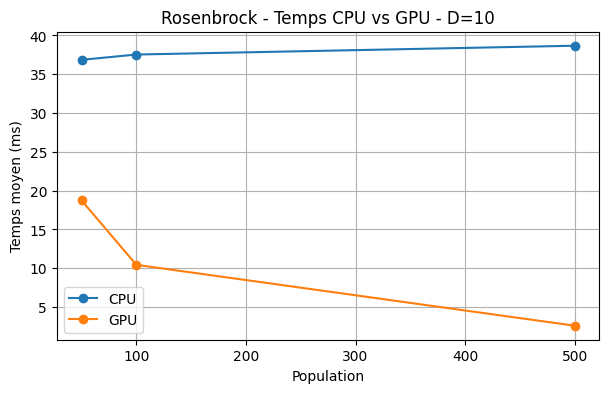

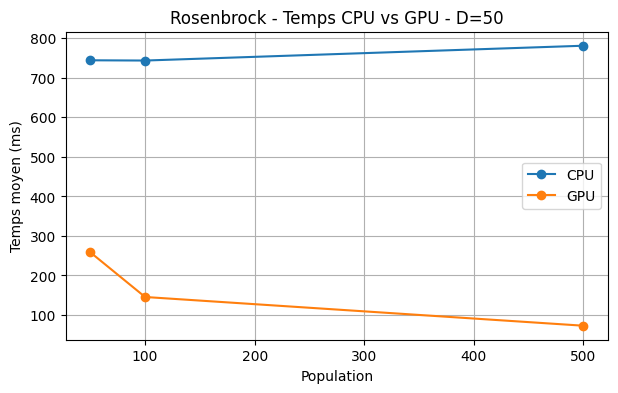

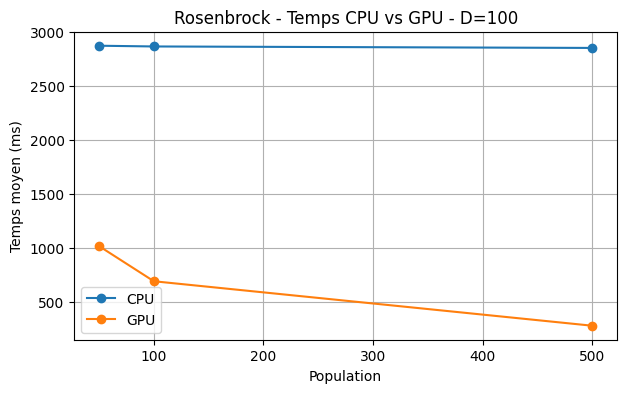

In [23]:
# 2. Temps CPU vs GPU
tracer_temps(f2_table, "Rosenbrock")


**Interprétation des temps d’exécution — Rosenbrock**

Les résultats obtenus sur la fonction Rosenbrock montrent que la version GPU est systématiquement plus rapide que la version CPU pour toutes les dimensions et toutes les tailles de population testées.

Le gain devient particulièrement important lorsque la population augmente. Pour une dimension donnée, le temps CPU reste globalement stable, tandis que le temps GPU diminue nettement lorsque le nombre d’individus augmente. Cela montre que le GPU exploite mieux le parallélisme lorsqu’il dispose de davantage d’individus à traiter simultanément.

On observe également que l’augmentation de la dimension entraîne une hausse du temps d’exécution pour les deux versions. Ce comportement est cohérent avec le fait que chaque évaluation de Rosenbrock doit parcourir davantage de variables lorsque la dimension augmente.


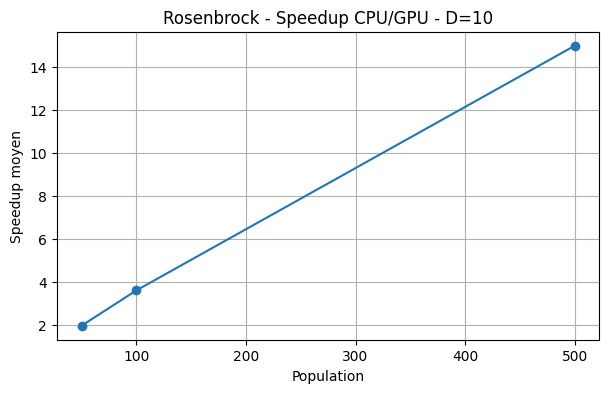

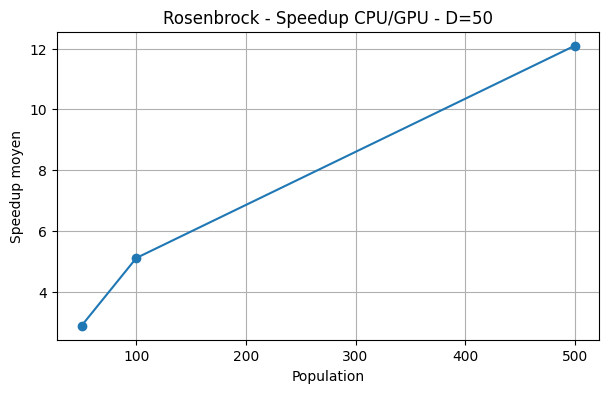

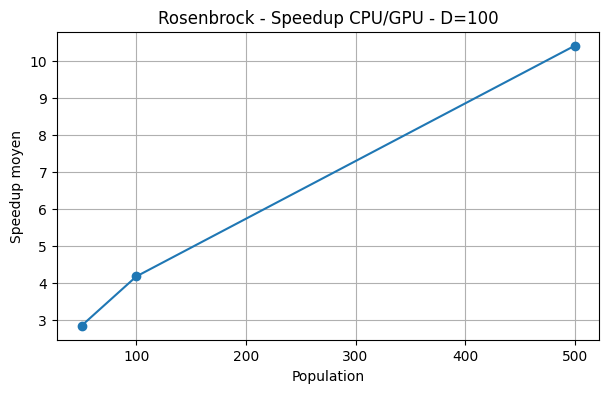

In [24]:
# 3. Speedup CPU/GPU
tracer_speedup(f2_table, "Rosenbrock")


**Interprétation du speedup CPU/GPU — Rosenbrock**

Les résultats montrent que le speedup obtenu avec la version GPU augmente nettement avec la taille de la population. Pour une dimension donnée, l’accélération reste modérée avec une population de 50 individus, puis devient beaucoup plus importante pour 100 et surtout 500 individus.

Par exemple, pour \(D=10\), le speedup moyen passe d’environ 1,97 avec \(NP=50\) à près de 15 avec \(NP=500\). Cette évolution confirme que l’implémentation CUDA tire davantage profit du parallélisme lorsque le nombre d’individus augmente.

Pour \(NP=500\), le speedup reste élevé pour toutes les dimensions testées. Il diminue légèrement lorsque la dimension augmente, mais le GPU conserve malgré tout un avantage important par rapport à l’exécution séquentielle sur CPU.


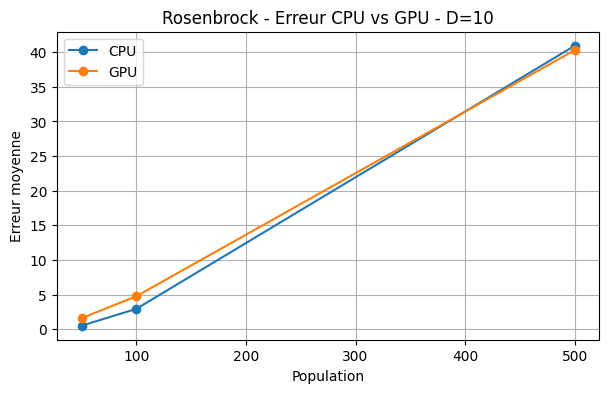

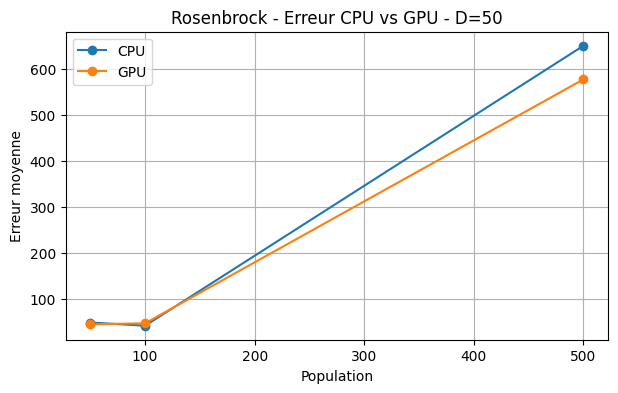

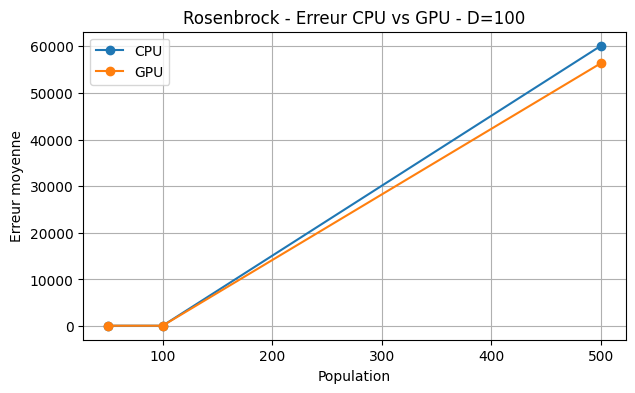

In [25]:
# 4. Erreurs CPU vs GPU
tracer_erreurs(f2_table, "Rosenbrock", log=False)


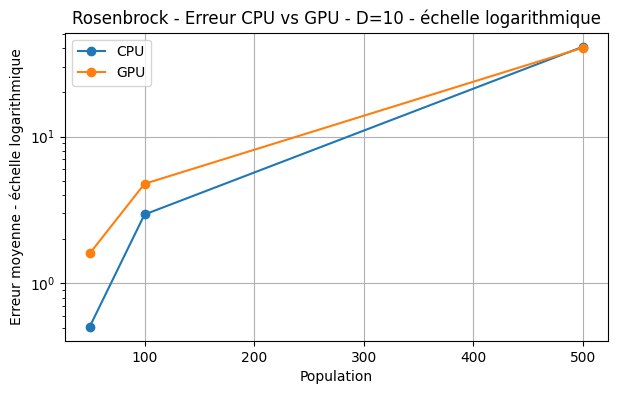

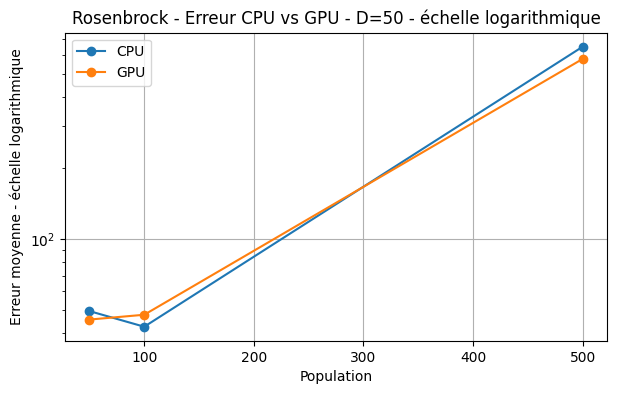

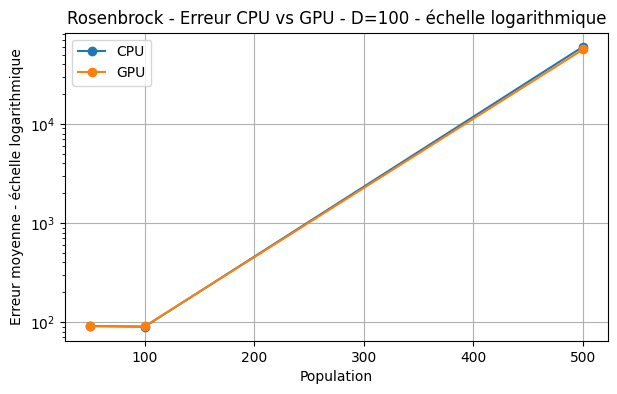

In [26]:
# 5. Erreurs CPU vs GPU en échelle logarithmique si possible
tracer_erreurs(f2_table, "Rosenbrock", log=True)


**Interprétation de la qualité des solutions — Rosenbrock**

La comparaison des erreurs moyennes montre que les versions CPU et GPU produisent globalement des résultats du même ordre de grandeur pour une même configuration. L’utilisation du GPU n’entraîne donc pas de dégradation systématique de la qualité des solutions par rapport à la version séquentielle.

En revanche, une population plus grande ne conduit pas nécessairement à une meilleure convergence. Pour \(NP=500\), l’erreur augmente fortement dans certaines configurations, en particulier lorsque \(D=100\).

Ce comportement peut s’expliquer par le budget d’évaluations fixé à \(MaxFES=10^4D\). Une population plus importante consomme davantage d’évaluations à chaque génération, ce qui réduit le nombre de générations disponibles avant l’arrêt de l’algorithme.

Ces résultats mettent donc en évidence un compromis entre la taille de la population, la qualité de convergence et le temps d’exécution. Dans ce cas, l’intérêt principal du GPU est l’accélération du calcul tout en maintenant une qualité de solution globalement comparable à celle du CPU.


In [27]:
# 6. Test de Wilcoxon apparié CPU/GPU
wilcoxon_f2 = wilcoxon_fonction(2)
display(wilcoxon_f2)


,Dimension,Population,Statistique W,p-value
0,10,50,13.0,0.160156
1,10,100,8.0,0.048828
2,10,500,27.0,1.000000
3,50,50,22.0,0.625000
4,50,100,25.0,0.845703
5,50,500,9.0,0.064453
6,100,50,26.0,0.921875
7,100,100,19.0,0.431641
8,100,500,16.0,0.275391


**Interprétation du test statistique de Wilcoxon — Rosenbrock**

Le test de Wilcoxon apparié a été utilisé pour comparer les erreurs obtenues par les versions CPU et GPU pour chaque combinaison de dimension et de taille de population. Le seuil de significativité est fixé à 5 %.

Pour huit configurations sur neuf, la p-value est supérieure à 0,05. Aucune différence statistiquement significative n’est donc mise en évidence entre les performances CPU et GPU pour ces configurations.

Une seule configuration, \(D=10\) et \(NP=100\), présente une p-value légèrement inférieure à 0,05 (\(p \approx 0,0488\)). Cette différence doit être signalée, mais elle reste isolée par rapport à l’ensemble des expériences réalisées sur Rosenbrock.

Globalement, le test de Wilcoxon confirme que la parallélisation GPU conserve une qualité de solution comparable à celle de la version séquentielle CPU, tout en permettant des gains importants en temps d’exécution.


**Conclusion de l’analyse F2 — Rosenbrock**

L’ensemble des résultats obtenus sur Rosenbrock montre que l’implémentation GPU permet de réduire fortement le temps d’exécution par rapport à la version séquentielle CPU. Le gain augmente avec la taille de la population et atteint environ 10 à 15 fois pour une population de 500 individus selon la dimension considérée.

Les erreurs obtenues par les versions CPU et GPU restent globalement du même ordre de grandeur. Le test de Wilcoxon va dans le même sens : pour huit configurations sur neuf, aucune différence statistiquement significative n’est détectée au seuil de 5 %.

Une population plus grande n’améliore toutefois pas systématiquement la convergence. Le cas \(D=100\), \(NP=500\) montre notamment une forte augmentation de l’erreur pour les deux versions. Cette évolution est cohérente avec le budget fixe \(MaxFES=10^4D\), qui limite davantage le nombre de générations lorsque la population augmente.

Dans l’ensemble, la version GPU apporte principalement un avantage en temps de calcul, tout en conservant une qualité de solution globalement comparable à celle de la version CPU sur la fonction Rosenbrock.


In [28]:
# 7. Sauvegarde des résultats détaillés
sauvegarder_analyse_fonction(2, f2_table, wilcoxon_f2)


rosenbrock_summary.csv et wilcoxon_F2.csv créés


### 11.3 F3 — Griewank — Taha


In [29]:
# 1. Filtrage CPU/GPU et tableau fusionné
f3_table = preparer_table_fonction(3)
display(f3_table)


,Dimension,Population,Erreur moyenne CPU,Ecart-type erreur CPU,Erreur moyenne GPU,Ecart-type erreur GPU,Temps moyen CPU (ms),Temps moyen GPU (ms),Speedup moyen,Ecart-type speedup,Erreur article
0,10,50,0.000000,0.000000,0.000000,0.000000,39.0648,24.2948,1.607932,0.045507,0.000
1,10,100,0.000000,0.000000,0.000000,0.000000,43.0377,12.9697,3.317696,0.186162,0.000
2,10,500,0.155895,0.015214,0.143704,0.011138,51.5634,3.0498,16.902493,0.828664,0.000
3,50,50,0.000000,0.000000,0.000000,0.000000,756.7784,375.4437,2.015657,0.039913,0.001
4,50,100,0.000000,0.000000,0.000000,0.000000,780.9872,200.5666,3.893909,0.064342,0.000
5,50,500,0.000541,0.000108,0.000570,0.000079,923.5895,89.5241,10.996858,3.449574,0.000
6,100,50,0.000000,0.000000,0.000000,0.000000,2918.2224,1447.8396,2.015598,0.009411,0.002
7,100,100,0.000000,0.000000,0.000000,0.000000,3119.7907,885.7128,3.522993,0.194402,0.005
8,100,500,0.105542,0.009645,0.105313,0.010328,4314.3426,333.7818,12.933955,0.464979,0.000


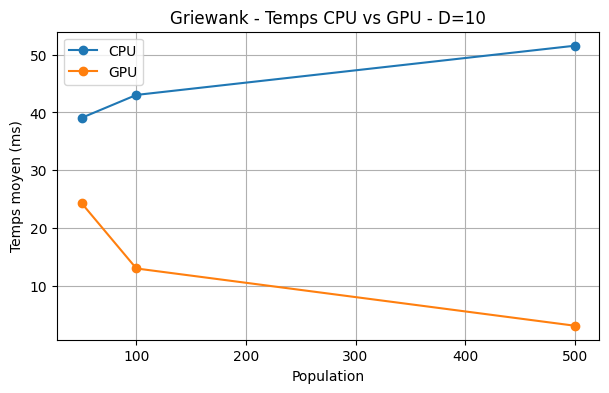

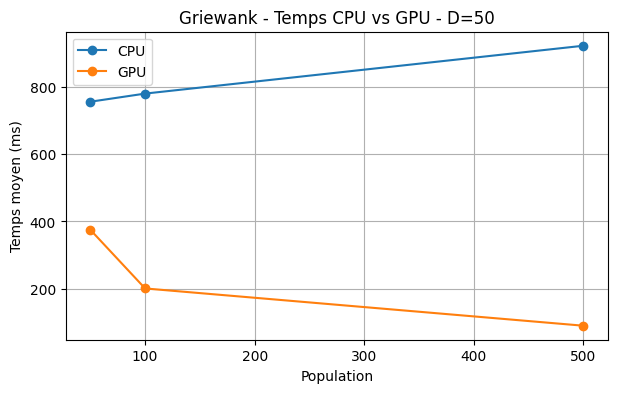

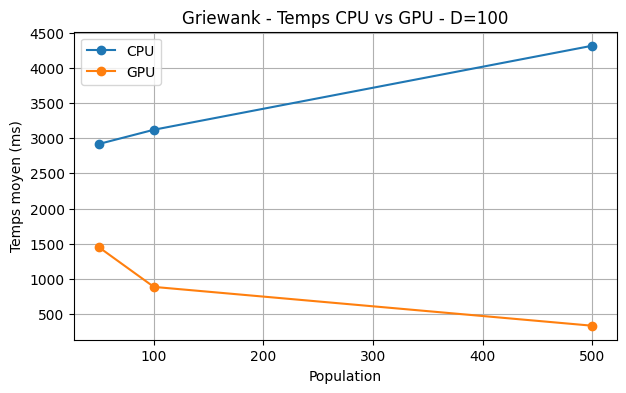

In [30]:
# 2. Temps CPU vs GPU
tracer_temps(f3_table, "Griewank")


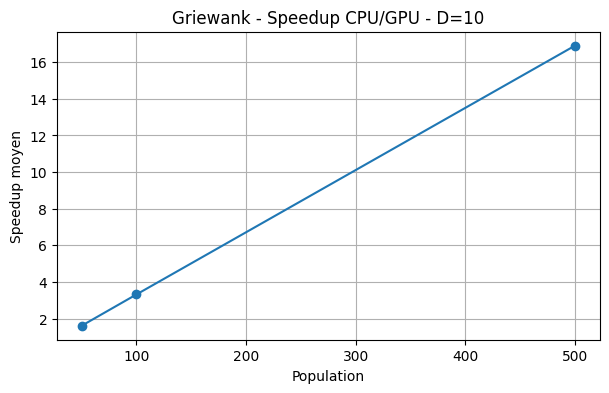

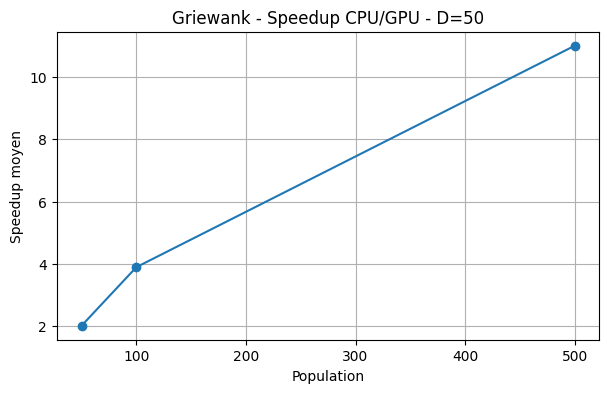

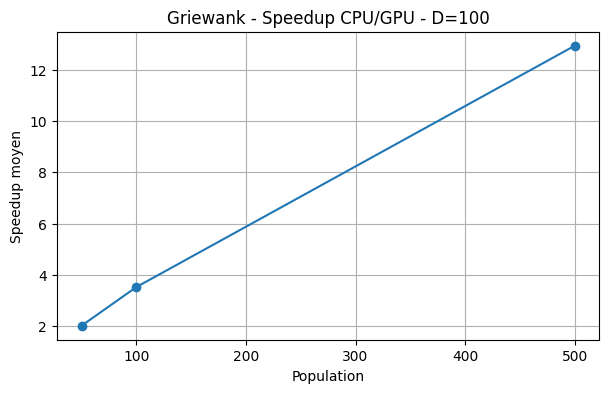

In [31]:
# 3. Speedup CPU/GPU
tracer_speedup(f3_table, "Griewank")


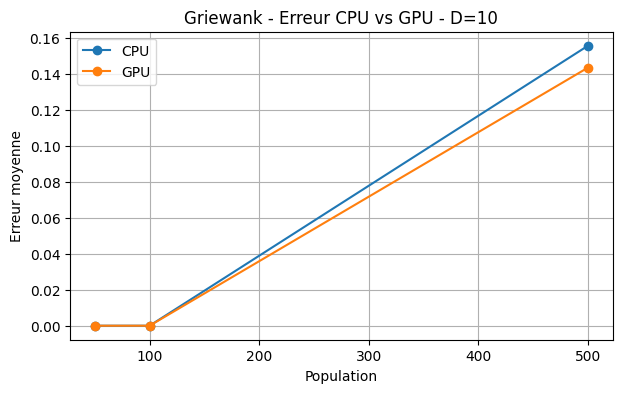

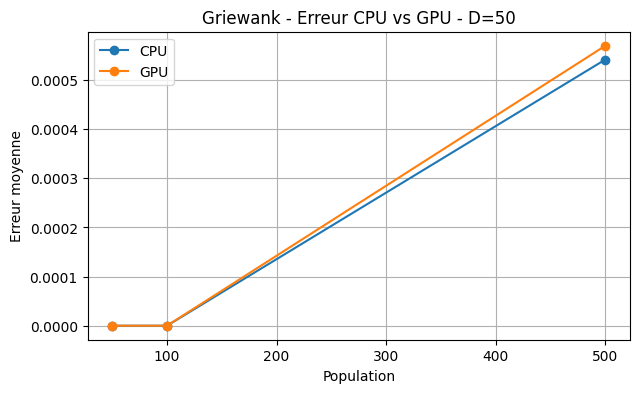

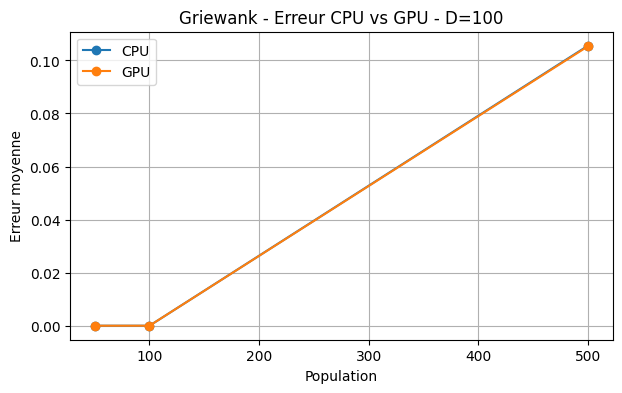

In [32]:
# 4. Erreurs CPU vs GPU
tracer_erreurs(f3_table, "Griewank", log=False)


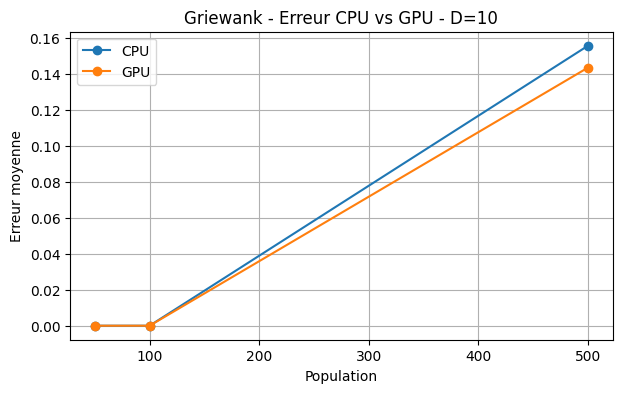

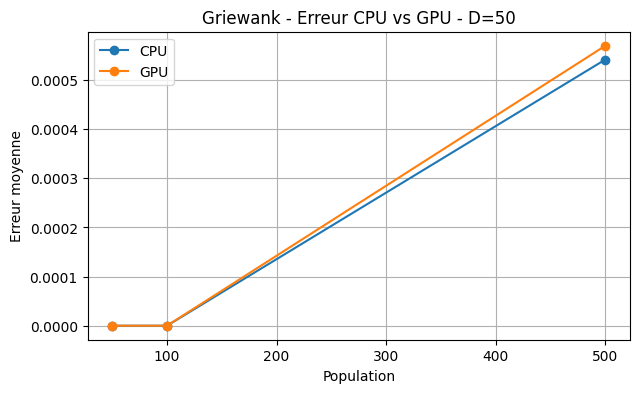

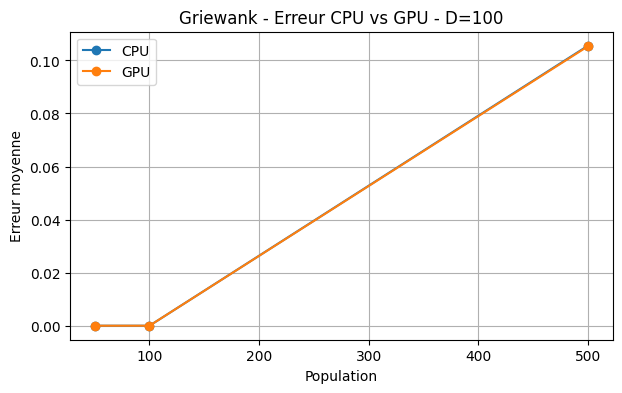

In [33]:
# 5. Erreurs CPU vs GPU en échelle logarithmique si possible
tracer_erreurs(f3_table, "Griewank", log=True)


In [34]:
# 6. Test de Wilcoxon apparié CPU/GPU
wilcoxon_f3 = wilcoxon_fonction(3)
display(wilcoxon_f3)


,Dimension,Population,Statistique W,p-value
0,10,50,0.0,1.000000
1,10,100,0.0,1.000000
2,10,500,11.0,0.105469
3,50,50,0.0,1.000000
4,50,100,0.0,1.000000
5,50,500,21.0,0.556641
6,100,50,0.0,1.000000
7,100,100,0.0,1.000000
8,100,500,27.0,1.000000


In [35]:
# 7. Sauvegarde des résultats détaillés
sauvegarder_analyse_fonction(3, f3_table, wilcoxon_f3)


griewank_summary.csv et wilcoxon_F3.csv créés


#### Compléments Griewank
Ces cellules complètent les analyses communes ci-dessus sans les modifier : (a) tableau et figure de synthèse en trois panneaux, avec une échelle qui accepte les erreurs égales à 0 ; (b) taux de succès, comparable à celui de l'article.

Erreur CPU (moy ± std) Erreur GPU (moy ± std)  Temps CPU (ms)  \
dim pop                                                                 
10  50                   0 ± 0                  0 ± 0            39.1   
    100                  0 ± 0                  0 ± 0            43.0   
    500          0.156 ± 0.015          0.144 ± 0.011            51.6   
50  50                   0 ± 0                  0 ± 0           756.8   
    100                  0 ± 0                  0 ± 0           781.0   
    500     0.000541 ± 0.00011      0.00057 ± 7.9e-05           923.6   
100 50                   0 ± 0                  0 ± 0          2918.2   
    100                  0 ± 0                  0 ± 0          3119.8   
    500         0.106 ± 0.0096           0.105 ± 0.01          4314.3   

         Temps GPU (ms)  Speedup  Erreur article  
dim pop                                           
10  50             24.3     1.61           0.000  
    100            13.0     3.32           0.000  
    500             3.0    16.90           0.000  
50  50            375.4     2.02           0.001  
    100           200.6     3.89           0.000  
    500            89.5    11.00           0.000  
100 50           1447.8     2.02           0.002  
    100           885.7     3.52           0.005  
    500           333.8    12.93           0.000

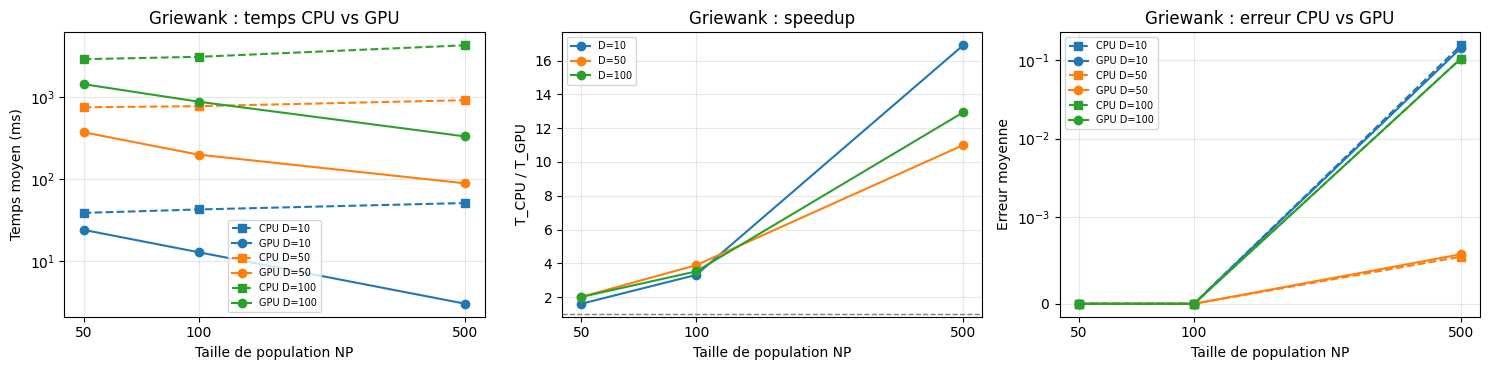

In [36]:
# Compléments : tableau de synthèse et figure en 3 panneaux
display(tableau_moy_std(3))
figure_synthese(3)


In [37]:
# Compléments : taux de succès (erreur < 1e-8), comparé à l'article
succes_f3 = taux_succes(3)
display(succes_f3)
succes_f3.to_csv("griewank_success_rate.csv", index=False)


mode,Dimension,Population,Succès CPU,Succès GPU,Succès article
0,10,50,1.0,1.0,1.00
1,10,100,1.0,1.0,1.00
2,10,500,0.0,0.0,1.00
3,50,50,1.0,1.0,0.92
4,50,100,1.0,1.0,1.00
5,50,500,0.0,0.0,1.00
6,100,50,1.0,1.0,0.84
7,100,100,1.0,1.0,0.96
8,100,500,0.0,0.0,0.96


**Interprétation F3 — Griewank Taha**

**1. Qualité : le GPU est-il aussi bon que le CPU ?**
Oui. Avec NP = 50 et NP = 100, l'erreur est nulle (à la précision de calcul) pour le CPU comme pour le GPU, en D = 10, 50 et 100. Avec NP = 500, il reste une petite erreur, mais elle est presque la même des deux côtés : 0,156 (CPU) et 0,144 (GPU) en D = 10, 0,0005 et 0,0006 en D = 50, 0,1055 et 0,1053 en D = 100. Le test de Wilcoxon ne voit pas de différence entre CPU et GPU (p = 0,106 ; 0,557 et 1,0, tous au-dessus de 0,05). Avec seulement 10 runs, on ne peut pas prouver que les deux sont égaux, mais on ne détecte aucune différence : passer sur GPU ne dégrade pas la qualité.

**2. Effet de la taille de la population**
L'erreur n'apparaît qu'avec NP = 500. Le test de Kruskal-Wallis le confirme : NP a un effet significatif (p ≈ 10⁻⁶ pour chaque dimension, en CPU et en GPU), et d'après les moyennes, c'est NP = 500 qui se distingue de NP = 50 et NP = 100. L'explication vient du budget, qui est fixe (10⁴ × D évaluations). Plus la population est grande, moins on a de générations : en D = 10, on a 1 999 générations avec NP = 50, 999 avec NP = 100 et seulement 199 avec NP = 500. Avec NP = 500, l'algorithme n'a donc pas assez de générations pour affiner la solution. Une grande population n'est pas forcément meilleure quand le budget est limité.

**3. Temps et speedup**
Le temps CPU dépend surtout de la dimension (environ 39 ms en D = 10, 757 ms en D = 50 et 2 918 ms en D = 100 avec NP = 50) et il augmente légèrement avec NP. Le temps GPU, lui, diminue quand NP augmente : il y a moins de générations à enchaîner, et plus d'individus sont traités en même temps (un thread par individu). Le speedup (T_CPU / T_GPU) passe de 1,6 (D = 10, NP = 50) à 16,9 (D = 10, NP = 500). Il va de 2,0 à 11,0 en D = 50 et de 2,0 à 12,9 en D = 100. Avec NP = 50, il y a peu d'individus et le GPU est peu utilisé ; avec NP = 500, il est bien mieux utilisé. Dans tous les cas testés, le GPU est plus rapide que le CPU.

**4. Taux de succès et figure de synthèse**
Le taux de succès est la proportion de runs dont l'erreur est inférieure à 10⁻⁸. Il vaut 1,0 pour NP = 50 et NP = 100, dans les trois dimensions, en CPU comme en GPU, et 0 pour NP = 500. Dans l'article, il vaut 0,84 à 1,00 pour NP = 50 et 100, et 0,96 à 1,00 pour NP = 500. On fait donc mieux que l'article pour NP = 50 et 100, mais on échoue à NP = 500. Comme le calcul est en simple précision, « succès » veut dire ici une erreur nulle à la précision de calcul.
Sur la figure en trois panneaux : à gauche (échelle logarithmique), le temps CPU est presque plat alors que le temps GPU baisse, donc l'écart se creuse quand NP augmente. Au centre, le speedup monte avec NP et est maximal en D = 10 (16,9). À droite (échelle symlog), les erreurs sont nulles pour NP = 50 et 100 puis montent à NP = 500, et les courbes CPU et GPU se superposent : la qualité est la même.

**5. Comparaison avec l'article**
Pour NP = 50 et NP = 100, nos erreurs sont aussi bonnes que celles de l'article, voire meilleures (0 contre 0,001 à 0,005 là où l'article n'a pas 0). Pour NP = 500, elles sont plus élevées (0,16 contre 0,00 en D = 10 ; 0,11 contre 0,00 en D = 100). Comme le CPU donne le même résultat que le GPU, cet écart ne vient pas de la parallélisation. On retrouve les mêmes tendances que dans l'article : le temps GPU diminue quand NP augmente, et une plus grande population n'améliore pas forcément la qualité à budget fixe.

**6. Limites**
- On a 10 runs par configuration (25 dans l'article).
- Les temps viennent d'une seule machine (Colab, Tesla T4) et d'un matériel différent de celui de l'article (une GTX 560 de 1 Go et un Xeon E5410 à 2,33 GHz) : on compare les tendances, pas les temps absolus.
- Le calcul est en simple précision (float) : une erreur « nulle » veut dire en dessous de la précision de calcul.
- L'écart avec l'article à NP = 500 n'est pas expliqué (pistes : détails d'implémentation, réglage de F et CR).


### 11.4 F4 — Rastrigin — Khadija


In [38]:
# 1. Filtrage CPU/GPU et tableau fusionné
f4_table = preparer_table_fonction(4)
display(f4_table)


,Dimension,Population,Erreur moyenne CPU,Ecart-type erreur CPU,Erreur moyenne GPU,Ecart-type erreur GPU,Temps moyen CPU (ms),Temps moyen GPU (ms),Speedup moyen,Ecart-type speedup,Erreur article
0,10,50,0.000000,0.000000,0.000000,0.000000,36.2775,20.9002,1.738327,0.097560,0.000
1,10,100,0.000000,0.000000,0.000000,0.000000,41.8176,11.6864,3.571759,0.304812,0.000
2,10,500,6.236288,0.719833,5.902141,1.116302,43.8530,2.6367,16.632415,0.155996,0.000
3,50,50,151.332220,6.300312,148.733360,10.770181,941.9871,314.2337,2.997772,0.123444,18.286
4,50,100,170.743490,11.916426,171.693980,7.966983,946.3608,169.6031,5.579862,0.079898,2.936
5,50,500,238.445250,6.739915,241.922570,8.541454,1091.4318,90.5865,13.028992,5.172855,28.345
6,100,50,542.155710,19.896765,543.157000,14.543817,3709.8455,1196.5423,3.100588,0.030975,63.166
7,100,100,589.050500,15.984981,587.400690,17.580436,3736.5446,761.8222,4.906140,0.099047,48.329
8,100,500,708.686550,26.577033,707.020020,20.604773,3734.6660,277.5575,13.457606,0.151537,40.891


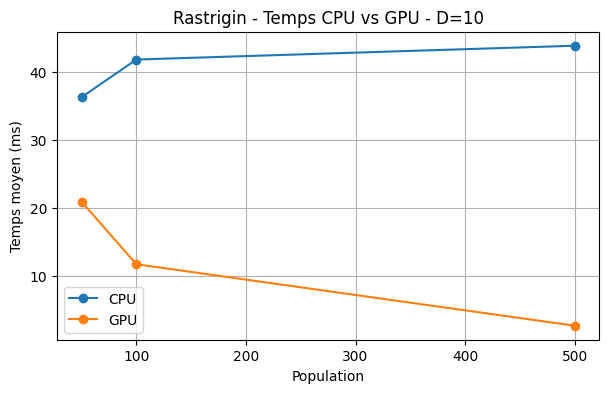

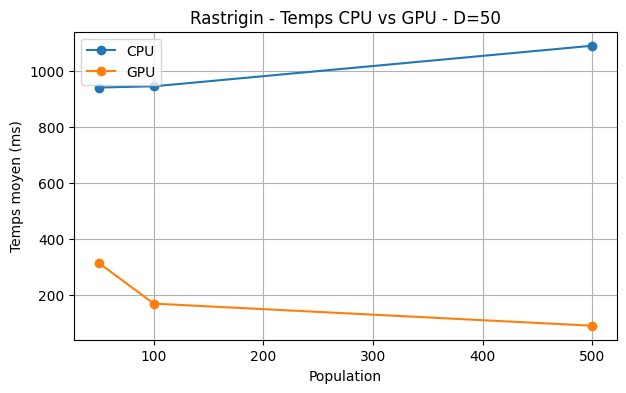

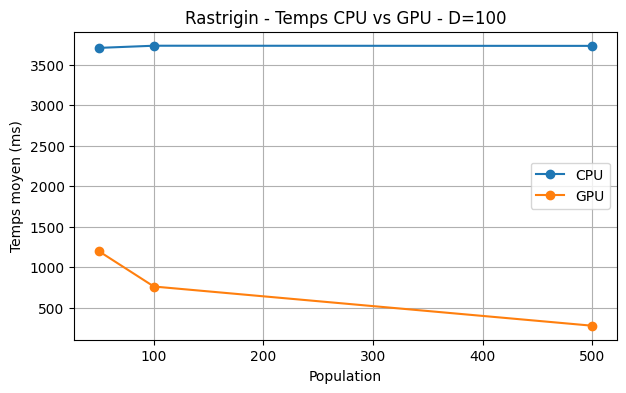

In [39]:
# 2. Temps CPU vs GPU
tracer_temps(f4_table, "Rastrigin")


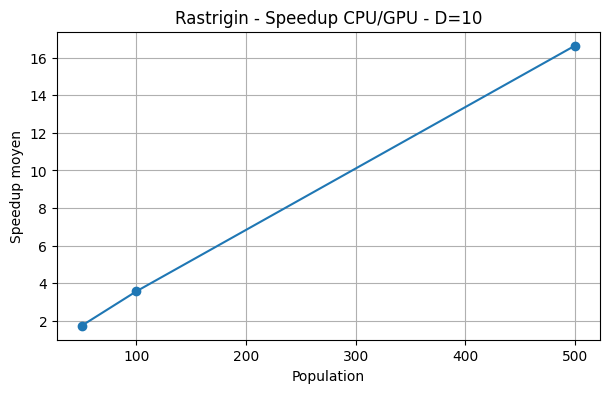

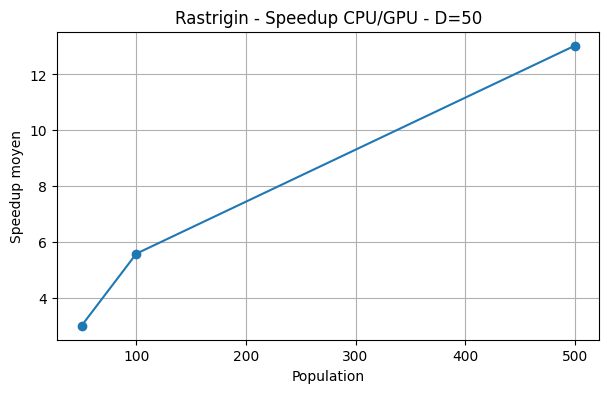

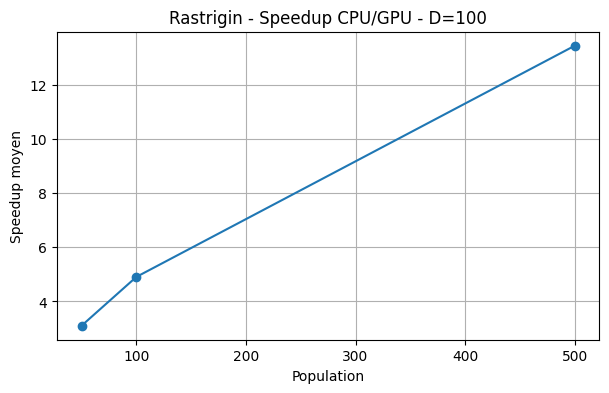

In [40]:
# 3. Speedup CPU/GPU
tracer_speedup(f4_table, "Rastrigin")


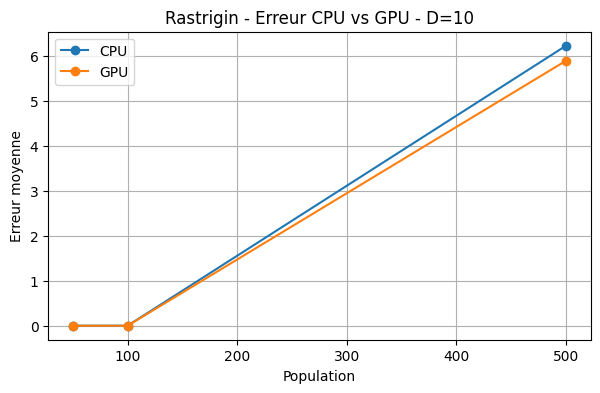

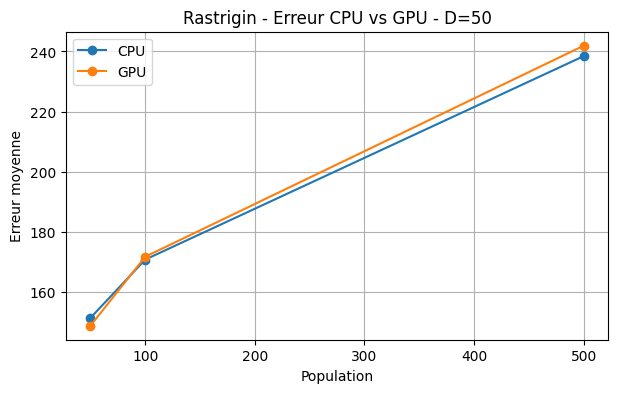

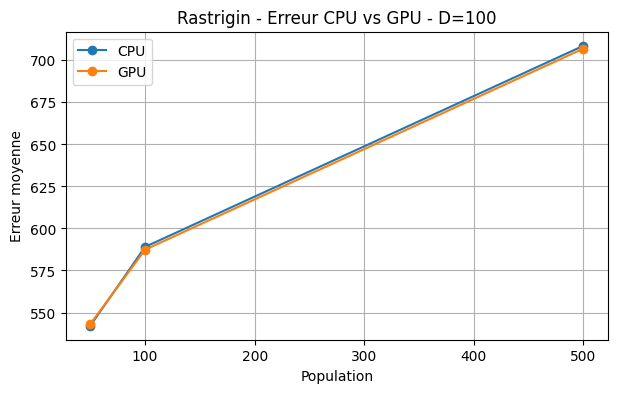

In [41]:
# 4. Erreurs CPU vs GPU
tracer_erreurs(f4_table, "Rastrigin", log=False)


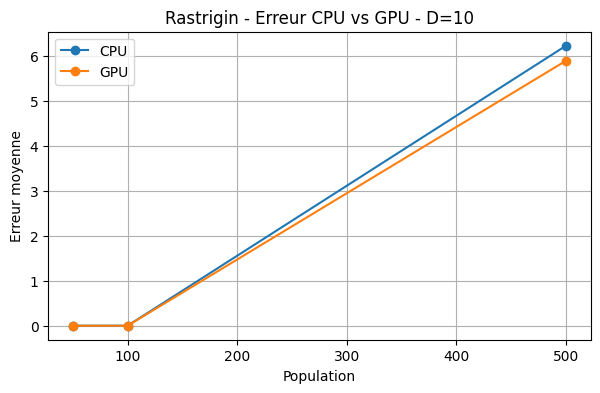

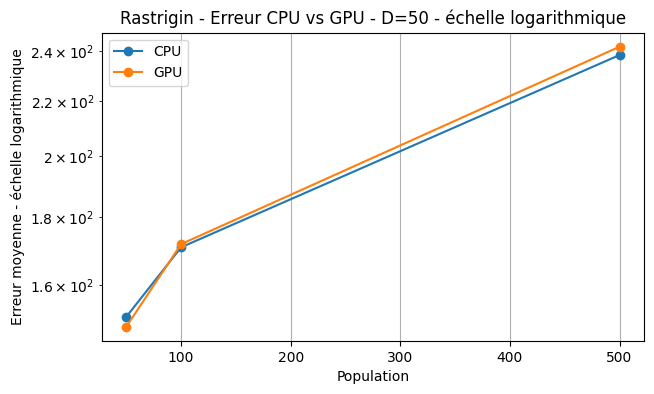

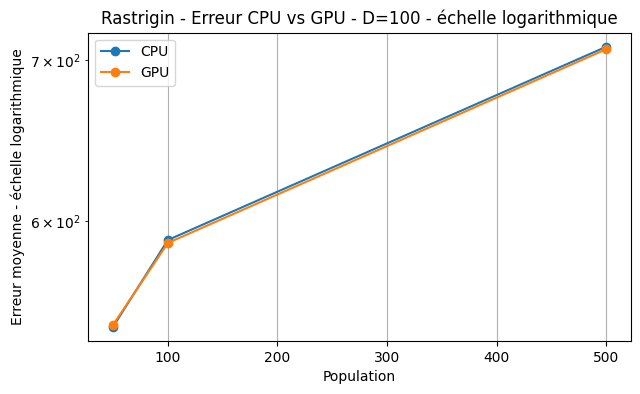

In [42]:
# 5. Erreurs CPU vs GPU en échelle logarithmique si possible
tracer_erreurs(f4_table, "Rastrigin", log=True)


In [43]:
# 6. Test de Wilcoxon apparié CPU/GPU
wilcoxon_f4 = wilcoxon_fonction(4)
display(wilcoxon_f4)


,Dimension,Population,Statistique W,p-value
0,10,50,0.0,1.000000
1,10,100,0.0,1.000000
2,10,500,23.0,0.695312
3,50,50,27.0,1.000000
4,50,100,23.0,0.695312
5,50,500,16.0,0.275391
6,100,50,25.0,0.845703
7,100,100,26.0,0.921875
8,100,500,23.0,0.695312


### Test statistique de Wilcoxon — Rastrigin

Le test de Wilcoxon apparié a été utilisé pour comparer les erreurs obtenues par les implémentations CPU et GPU de Differential Evolution.

Pour les neuf configurations étudiées, aucune différence statistiquement significative n'a été détectée au seuil de 5 %.

Ces résultats indiquent que les deux implémentations présentent une qualité d'optimisation statistiquement comparable dans les expériences réalisées, sans démontrer pour autant leur équivalence exacte.

L'utilisation du GPU permet ainsi de réduire les temps d'exécution sans qu'une différence systématique de précision soit mise en évidence sur Rastrigin.

In [44]:
# 7. Sauvegarde des résultats détaillés
sauvegarder_analyse_fonction(4, f4_table, wilcoxon_f4)


rastrigin_summary.csv et wilcoxon_F4.csv créés


**Interprétation : Shifted Rastrigin**

Les résultats montrent que la fonction Rastrigin est plus difficile à optimiser que Sphere, en raison de la présence de nombreux minima locaux.

Pour D = 10 et NP = 50, les erreurs moyennes sont nulles à la précision enregistrée pour les versions CPU et GPU. Cependant, lorsque la dimension augmente, les erreurs deviennent plus importantes.

Pour D = 100 et NP = 500, l'erreur moyenne atteint 708,69 sur CPU et 707,02 sur GPU. Les écarts-types des erreurs sont respectivement de 26,58 et 20,60. Ces résultats indiquent que les deux implémentations présentent une qualité de solution proche, malgré une difficulté d'optimisation élevée.

En revanche, les performances temporelles sont nettement différentes. Pour cette même configuration, le temps moyen est de 3 734,67 ms sur CPU contre 277,56 ms sur GPU. Le speedup moyen enregistré est de 13,46.

**Conclusion :** CUDA améliore considérablement la vitesse d'exécution de Differential Evolution sur Rastrigin, mais cette accélération ne garantit pas une meilleure convergence vers l'optimum global.


## 12. Comparaison globale des quatre fonctions

In [45]:
# Résumé global du speedup selon la population

global_speedup = (
    paired.groupby(["func", "dim", "pop"])
    .agg(
        time_cpu=("time_ms_cpu", "mean"),
        time_gpu=("time_ms_gpu", "mean")
    )
    .reset_index()
)

global_speedup["speedup"] = (
    global_speedup["time_cpu"] / global_speedup["time_gpu"]
)

speedup_par_population = (
    global_speedup.groupby("pop")["speedup"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

display(speedup_par_population)

,pop,mean,std,min,max
0,50,2.713484,1.099193,1.607949,5.063252
1,100,4.067127,0.908314,2.479046,5.579856
2,500,12.314316,2.659957,9.048679,16.907141


In [46]:
speedup_par_fonction = (
    global_speedup.groupby("func")["speedup"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

speedup_par_fonction["Fonction"] = speedup_par_fonction["func"].map({
    1: "Sphere",
    2: "Rosenbrock",
    3: "Griewank",
    4: "Rastrigin"
})

display(
    speedup_par_fonction[
        ["Fonction", "mean", "std", "min", "max"]
    ]
)

,Fonction,mean,std,min,max
0,Sphere,5.786025,3.240241,1.876264,10.307366
1,Rosenbrock,6.278784,4.549244,1.966912,14.894563
2,Griewank,6.280359,5.630970,1.607949,16.907141
3,Rastrigin,7.114734,5.441332,1.735749,16.631775


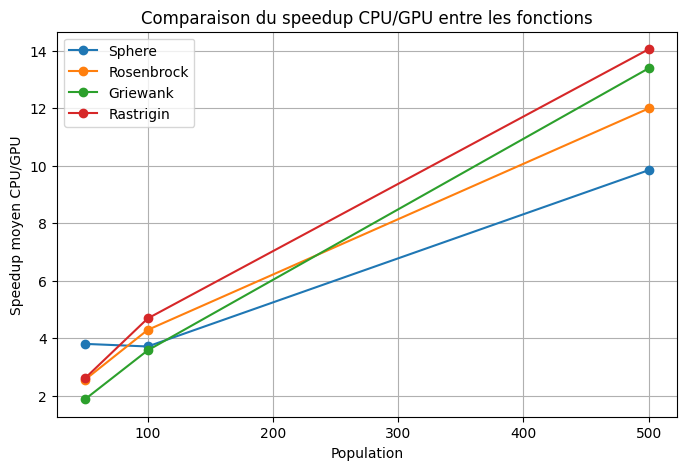

In [47]:
plt.figure(figsize=(8, 5))

for func, nom in noms.items():
    sub = global_speedup[global_speedup["func"] == func]

    valeurs = (
        sub.groupby("pop")["speedup"]
        .mean()
        .reset_index()
    )

    plt.plot(
        valeurs["pop"],
        valeurs["speedup"],
        marker="o",
        label=nom
    )

plt.xlabel("Population")
plt.ylabel("Speedup moyen CPU/GPU")
plt.title("Comparaison du speedup CPU/GPU entre les fonctions")
plt.legend()
plt.grid(True)
plt.show()

## 12. Comparaison globale des quatre fonctions

L’analyse globale montre que la version GPU est systématiquement plus rapide que la version séquentielle CPU pour les quatre fonctions étudiées : Sphere, Rosenbrock, Griewank et Rastrigin.

L’effet le plus important est celui de la taille de la population. En moyenne sur l’ensemble des fonctions et dimensions, le speedup passe d’environ **2,71** pour une population de 50 individus à **4,07** pour 100 individus, puis atteint environ **12,31** pour 500 individus. Cela confirme que le GPU devient particulièrement avantageux lorsque le nombre d’individus à traiter augmente, car davantage d’opérations peuvent être exécutées en parallèle.

La comparaison par fonction montre également des différences de comportement. Le speedup moyen global est d’environ **5,79** pour Sphere, **6,28** pour Rosenbrock, **6,28** pour Griewank et **7,11** pour Rastrigin. Les accélérations maximales les plus élevées sont obtenues avec Griewank, avec environ **16,91**, et Rastrigin, avec environ **16,63**. Rosenbrock atteint environ **14,89**, tandis que Sphere atteint environ **10,31**.

Le graphique global confirme cette tendance : pour toutes les fonctions, l’accélération augmente avec la population. Pour une population de 50 individus, le gain GPU reste relativement modéré, alors qu’il devient très important pour une population de 500 individus. Rastrigin et Griewank sont les fonctions qui profitent le plus fortement du parallélisme GPU dans les grandes populations.

Concernant la qualité des solutions, les analyses détaillées ont montré que les versions CPU et GPU produisent globalement des résultats du même ordre de grandeur. Les tests de Wilcoxon confirment que, dans la grande majorité des configurations, aucune différence statistiquement significative n’est détectée entre les erreurs obtenues par les deux versions. Le principal avantage de l’implémentation CUDA est donc l’accélération du calcul plutôt qu’une modification systématique de la qualité de convergence.

L’influence de la dimension dépend davantage de la fonction considérée. L’augmentation de la dimension accroît généralement le coût de calcul et peut rendre l’optimisation plus difficile, notamment pour Rosenbrock et Rastrigin. Sphere et Griewank présentent au contraire une convergence plus régulière dans plusieurs configurations.

Enfin, l’augmentation de la population n’améliore pas nécessairement la qualité des solutions. Le budget d’évaluations étant fixé à \(MaxFES = 10^4D\), une population plus grande consomme davantage d’évaluations à chaque génération et réduit donc le nombre de générations disponibles. Cela explique pourquoi certaines configurations avec \(NP=500\) présentent une erreur plus élevée malgré un speedup GPU important.

Dans l’ensemble, les résultats montrent que la parallélisation CUDA est particulièrement efficace pour les grandes populations. Elle permet d’obtenir des accélérations importantes tout en conservant une qualité de solution globalement comparable à celle de la version séquentielle CPU.

## 13. Fichiers produits
À la fin de l’exécution du notebook, le dossier `DE_final` contient notamment :
- `summary_final.csv` et `speedup_final.csv` ;
- pour chaque fonction : `<fonction>_summary.csv` et `wilcoxon_F<k>.csv` ;
- dossier `images/` : un graphique `.png` par fonction, par dimension et par type (temps, speedup, erreur).
